# 🌌 Gravitational-Wave Explorer (LIGO open data)

Every time you run this notebook it will:
1. **Pick a new gravitational-wave event** at random from the public GWOSC catalogs
   (Gravitational Wave Open Science Center: LIGO + Virgo + KAGRA).
2. **Download the real detector data** around the merger.
3. **Clean it** (whitening + band-pass) so the faint signal stands out of the noise.
4. **Turn it into sound** (.wav files + an in-notebook player) with a printed listening guide.
5. **Turn it into a spectrogram** (frequency vs. time) with a printed reading guide.
6. **Report the analysis**: type of signal, type of source, and name of the source.
7. **Generate GIF** of the source and its impact
8. **Save and download** everything to your computer
Requirements: internet connection, Python 3.9+. Run cells from top to bottom.
Cells with "EDIT ME" markers contain the knobs you can change.

#1.Install the software

In [1]:
# ============================================================================
# CELL 1 — INSTALL THE SOFTWARE  (run once per session)
# ============================================================================
# PHYSICAL PURPOSE
#   LIGO, Virgo and KAGRA release their detector data for free. Two Python
#   libraries let us reach and analyse it:
#     * gwosc : talks to GWOSC (the Gravitational Wave Open Science Center) to
#               list events and fetch their measured properties (masses, SNR...).
#     * gwpy  : LIGO's own analysis toolkit (time series, whitening, filtering,
#               Q-transform spectrograms).
#
# "%pip" is a Jupyter "magic command": it runs pip (Python's installer) inside
# THIS notebook's Python environment. "-q" means "quiet" (less printed text).
# You only need to re-run this cell if a later cell says "No module named ...".
%pip install -q gwpy gwosc

#2.Imports and constants

In [2]:
# ============================================================================
# CELL 2 — IMPORT LIBRARIES AND DEFINE PHYSICAL CONSTANTS
# ============================================================================
# PHYSICAL PURPOSE
#   Load the toolboxes we need, and define the one physical constant that
#   converts "solar masses" into "seconds" (used in the chirp formulas).

# ---- Standard-library tools (they come with Python) -----------------------
# "os" lets us check, create and delete files (used for the "already seen" list).
import os
# "re" = regular expressions, a pattern-matching tool for text. We use it to
# remove version tags such as "-v3" from event names like "GW150914-v3".
import re
# "random" gives random numbers. We use it to pick a different event each run.
import random

# ---- Numbers and plots -----------------------------------------------------
# numpy: fast arrays and maths. Every signal in this notebook is a numpy array.
import numpy as np
# matplotlib.pyplot: the plotting library (we call it "plt" for short).
import matplotlib.pyplot as plt

# ---- Signal processing -----------------------------------------------------
# spectrogram: chops a signal into short pieces and measures the frequencies
# present in each piece. Result = a "frequency versus time" map.
from scipy.signal import spectrogram
# tukey: a smooth "fade-in / fade-out" shape. Multiplying audio by it avoids
# loud clicks at the start and end of the sound.
from scipy.signal.windows import tukey
# wavfile: lets us save sound as a .wav file you can keep and share.
from scipy.io import wavfile

# ---- Notebook display helpers ----------------------------------------------
# Audio: an in-notebook play button. display: shows objects in the notebook.
from IPython.display import Audio, display

# ---- Astronomy helper ------------------------------------------------------
# Time: converts GPS seconds (what LIGO uses) into normal calendar dates (UTC).
from astropy.time import Time

# ---- LIGO open-data tools --------------------------------------------------
# datasets: lists the events available in each GWOSC catalog.
from gwosc import datasets
# fetch_event_json: downloads one event's measured properties (masses, SNR...).
from gwosc.api import fetch_event_json
# TimeSeries: gwpy's container for detector data (strain versus time).
from gwpy.timeseries import TimeSeries

# Tell Jupyter to draw plots directly below the cell that creates them.
%matplotlib inline

# ---- Physical constant -------------------------------------------------------
# G * (one solar mass) / c^3, in SECONDS  (G = gravitational constant, c = speed
# of light). General relativity formulas become simple when masses are written
# as times. Example: a 30-solar-mass object has "T = 30 * T_SUN = 0.000148 s".
T_SUN = 4.925491e-6

#3.Settings (the knobs)

In [3]:
# ============================================================================
# CELL 3 — SETTINGS  (EDIT ME)
# ============================================================================
# PHYSICAL PURPOSE
#   Every number that controls the analysis lives here, so a beginner can change
#   behaviour without touching the real code. Change a value, then re-run
#   Cells 3 → 12.

# ---- Which event? ----------------------------------------------------------
# None = pick a random, not-yet-seen event each run (default).
# To study one specific event instead, write its name, e.g. FORCE_EVENT = "GW150914"
FORCE_EVENT = None

# Seed for the random generator. None = truly different every run.
# A fixed number (e.g. 42) makes the random pick repeatable (useful for teaching).
RANDOM_SEED = None

# Minimum "network matched-filter SNR" (signal-to-noise ratio) to accept an event.
# SNR ~ how many times louder the signal is than the noise. Events below ~10 are
# very hard to see/hear by eye. Lower it (e.g. 6) to allow faint events.
MIN_NETWORK_SNR = 10.0

# File that remembers which events you've already seen, so each run is NEW.
HISTORY_FILE = "gw_seen_events.txt"
# True = forget the history and allow repeats again (set back to False afterwards).
RESET_HISTORY = False

# How many random candidates to examine before giving up on finding one that
# passes the SNR/mass checks. Raise this if you set a high MIN_NETWORK_SNR.
MAX_CANDIDATE_TRIES = 40

# ---- Where to look for events ------------------------------------------------
# GWOSC catalog names. "GWTC" is the cumulative (always growing) LVK catalog; the
# others are earlier releases. Names that don't exist are skipped safely.
CATALOGS_TO_SEARCH = ["GWTC", "GWTC-1-confident", "GWTC-2.1-confident",
                      "GWTC-3-confident", "GWTC-4.0"]

# Backup list of famous events, used only if the online catalog can't be reached.
FALLBACK_EVENTS = ["GW150914", "GW151226", "GW170104", "GW170608", "GW170814",
                   "GW170817", "GW190412", "GW190425", "GW190521", "GW190814"]

# ---- Detector data ------------------------------------------------------------
# Detector preference order. H1 = LIGO Hanford (Washington, USA),
# L1 = LIGO Livingston (Louisiana, USA), V1 = Virgo (Italy).
DETECTOR_PREFERENCE = ["H1", "L1", "V1"]

# Samples per second of the data we download (4096 = 4 kHz: plenty for LIGO's
# most sensitive range, ~20-1000 Hz).
SAMPLE_RATE = 4096

# Extra seconds of data fetched on each side of the signal window. Filters and
# noise estimates misbehave at the edges of data, so we fetch extra and throw
# the edges away later. Larger = better noise estimate but a bigger download.
EDGE_PAD_SECONDS = 14.0

# ---- Filtering (the "band" where LIGO hears gravitational waves) -------------
# Below ~20 Hz the detectors are swamped by ground vibrations; above ~500 Hz
# most of these signals are already finished. We keep only the band in between.
BAND_LOW_HZ = 20.0
BAND_HIGH_HZ = 500.0

# ---- Audio ----------------------------------------------------------------------
# Output sound sample rate (44100 = CD quality; every device can play it).
AUDIO_RATE = 44100
# How much to speed up the "pitch-raised" version. 4 = four times higher pitch
# and four times shorter. Laptop speakers are poor below ~100 Hz, so this helps.
SPEEDUP_FACTOR = 4.0
# Longest stretch (seconds) of the pre-merger signal that we turn into sound/plot.
# Neutron-star mergers last minutes; this keeps the clip a sensible length.
MAX_SECONDS_BEFORE_MERGER = 30.0

# ---- Plots ------------------------------------------------------------------------
# True = also draw the LIGO-standard "Q-transform" spectrogram (Cell 11).
MAKE_Q_TRANSFORM = True
# True = draw the theoretical chirp curve on top of the spectrogram so you can
# compare theory with the measured data.
SHOW_THEORY_CHIRP = True

# ---- Classification thresholds (solar masses) -------------------------------------
# Heaviest possible neutron star is thought to be ~2-3 solar masses.
NS_MAX_MASS = 3.0
# Objects between ~3 and ~5 solar masses are in the so-called "lower mass gap":
# we can't be sure whether they are neutron stars or black holes.
MASS_GAP_UPPER = 5.0

#4.Helper functions

In [4]:
# ============================================================================
# CELL 4 — HELPER FUNCTIONS (small reusable tools)
# ============================================================================
# PHYSICAL PURPOSE
#   Contains the physics formulas (chirp mass, chirp frequency, time spent in
#   the detector band) and the rule-based classifier for the source type.
#   Running this cell only DEFINES the functions; nothing is printed.


def strip_version(event_name):
    # GWOSC names may end in a version tag ("-v3"). Remove it with a regular
    # expression: "-v" followed by one or more digits (\d+) at the end ($).
    return re.sub(r"-v\d+$", "", event_name)


def to_float(value):
    # Catalog entries can be missing (JSON "null" becomes Python None).
    # This converts a value to a float, or returns None if that is impossible.
    try:
        # If the value is None keep it None, otherwise convert it to a number.
        return None if value is None else float(value)
    except (TypeError, ValueError):
        # Anything that isn't a clean number is treated as "unknown".
        return None


def fmt(value, unit="", digits=1):
    # Pretty-printing helper: shows "unknown" for missing numbers.
    if value is None:
        return "unknown"
    # Format with the requested number of decimals, then append the unit.
    return f"{value:.{digits}f} {unit}".strip()


def chirp_mass(m1, m2):
    # The "chirp mass" is the particular combination of the two masses that
    # controls how fast the gravitational-wave frequency rises. It is the
    # best-measured mass in any signal:  Mc = (m1*m2)^(3/5) / (m1+m2)^(1/5).
    return (m1 * m2) ** (3.0 / 5.0) / (m1 + m2) ** (1.0 / 5.0)


def seconds_in_band(mc_detector_frame, f_low):
    # Leading-order (Newtonian) estimate of how many seconds the signal spends
    # between frequency f_low and the merger:
    #    tau = (5/256) * (G*Mc/c^3)^(-5/3) * (pi*f_low)^(-8/3)
    # Heavy systems = short signals; neutron stars = long signals.
    return (5.0 / 256.0) * (T_SUN * mc_detector_frame) ** (-5.0 / 3.0) \
           * (np.pi * f_low) ** (-8.0 / 3.0)


def chirp_frequency(tau, mc_detector_frame):
    # Predicted gravitational-wave frequency [Hz] at "tau" seconds before merger:
    #    f = (1/pi) * (5/(256*tau))^(3/8) * (G*Mc/c^3)^(-5/8)
    # Valid for the inspiral (before the final fraction of a second).
    return (1.0 / np.pi) * (5.0 / (256.0 * tau)) ** (3.0 / 8.0) \
           * (T_SUN * mc_detector_frame) ** (-5.0 / 8.0)


def classify_source(mass_a, mass_b, final_mass_value):
    # Rule-based guess of the source type from the two component masses.
    # (Real LVK papers use full Bayesian analysis; this is a simple, honest rule.)
    # "heavy" = the larger mass, "light" = the smaller mass.
    heavy = max(mass_a, mass_b)
    light = min(mass_a, mass_b)

    # Both objects below the neutron-star limit -> two neutron stars.
    if heavy <= NS_MAX_MASS:
        return ("Binary neutron star (BNS) merger",
                "Both objects are lighter than ~3 solar masses, so both are most "
                "likely neutron stars. Such mergers can also emit light (a kilonova).")
    # Only the lighter object is below the limit -> neutron star + black hole.
    if light <= NS_MAX_MASS:
        return ("Neutron star - black hole (NSBH) merger",
                "One object is lighter than ~3 solar masses (a neutron star) and the "
                "other is heavier (a black hole).")
    # The lighter object sits in the 3-5 solar-mass "mass gap".
    if light < MASS_GAP_UPPER:
        return ("Compact binary with a 'mass-gap' object (3-5 solar masses)",
                "The lighter object is too heavy for a typical neutron star yet lighter "
                "than typical black holes, so its nature is uncertain.")
    # Final black hole above 100 solar masses -> intermediate-mass black hole.
    if final_mass_value is not None and final_mass_value >= 100.0:
        return ("Binary black hole (BBH) merger forming an intermediate-mass black hole",
                "Both objects are black holes and the remnant exceeds 100 solar masses, "
                "the range called 'intermediate-mass'.")
    # Everything else: two stellar-mass black holes.
    return ("Binary black hole (BBH) merger",
            "Both objects are heavier than ~5 solar masses, so both are black holes.")


def fetch_event_info(event_name, catalog_name):
    # Downloads the measured properties of ONE event from GWOSC.
    # We first try with the catalog name (precise), then without it (flexible).
    for catalog_try in (catalog_name, None):
        try:
            # Ask GWOSC for the event's JSON description.
            reply = fetch_event_json(event_name, catalog=catalog_try)
            # The reply holds a dictionary "events"; take its first (only) entry.
            return next(iter(reply["events"].values()))
        except Exception:
            # Any network or lookup problem: try the next option.
            continue
    # Both attempts failed: report "no information".
    return None

#5.Pick a new event

In [5]:
# ============================================================================
# CELL 5 — PICK A NEW GRAVITATIONAL-WAVE EVENT
# ============================================================================
# PHYSICAL PURPOSE
#   Choose the astrophysical source we will study. We want an event that
#   (a) has measured masses (needed to classify it), and
#   (b) is loud enough (SNR) that the signal is visible/audible, and
#   (c) we haven't looked at before in earlier runs.

# ---- 5.1 Seed the random generator (only if the user asked for repeatability) ---
if RANDOM_SEED is not None:
    random.seed(RANDOM_SEED)

# ---- 5.2 Optionally wipe the memory of previously seen events ----------------------
if RESET_HISTORY and os.path.exists(HISTORY_FILE):
    os.remove(HISTORY_FILE)

# ---- 5.3 Build the candidate list: {event name: catalog it was found in} -----------
candidate_catalog = {}

if FORCE_EVENT is not None:
    # The user named an event explicitly, so that is the only candidate.
    candidate_catalog[FORCE_EVENT] = None
else:
    # Ask each catalog in turn for its list of events.
    for catalog_name in CATALOGS_TO_SEARCH:
        try:
            names = datasets.find_datasets(type="event", catalog=catalog_name)
        except Exception as error:
            # A catalog that doesn't exist (or no internet) is simply skipped.
            print(f"(skipping catalog '{catalog_name}': {error})")
            continue
        for raw_name in names:
            # Remove "-v3"-style tags; "setdefault" keeps the first catalog seen.
            candidate_catalog.setdefault(strip_version(raw_name), catalog_name)

    # If nothing could be fetched, fall back to the famous-event list.
    if len(candidate_catalog) == 0:
        print("Could not read the online catalogs; using the built-in backup list.")
        for fallback_name in FALLBACK_EVENTS:
            candidate_catalog[fallback_name] = None

print(f"Candidate events available: {len(candidate_catalog)}")

# ---- 5.4 Load the list of events seen in earlier runs -------------------------------
seen_events = set()
if os.path.exists(HISTORY_FILE):
    # Read the file; each line is one event name.
    with open(HISTORY_FILE) as history_file:
        seen_events = {line.strip() for line in history_file if line.strip()}

# Keep only events NOT seen yet (or the forced event).
if FORCE_EVENT is not None:
    unseen = [FORCE_EVENT]
else:
    unseen = [name for name in candidate_catalog if name not in seen_events]
    # If we have visited everything, start over rather than crashing.
    if len(unseen) == 0:
        print("You have now seen every available event! Starting the list over.")
        unseen = list(candidate_catalog)
        if os.path.exists(HISTORY_FILE):
            os.remove(HISTORY_FILE)

# Shuffle so the pick is random.
random.shuffle(unseen)

# ---- 5.5 Examine candidates until one passes the checks -------------------------------
# With a forced event we skip the SNR check (you asked for that event specifically).
snr_threshold = 0.0 if FORCE_EVENT is not None else MIN_NETWORK_SNR

event_name = None   # will hold the chosen event's name
info = None         # will hold the chosen event's properties (a dictionary)

for candidate in unseen[:MAX_CANDIDATE_TRIES]:
    # Download this candidate's properties.
    candidate_info = fetch_event_info(candidate, candidate_catalog[candidate])
    if candidate_info is None:
        continue  # download failed, try the next one

    # Pull out the numbers we need (None if the catalog has no value).
    cand_m1 = to_float(candidate_info.get("mass_1_source"))
    cand_m2 = to_float(candidate_info.get("mass_2_source"))
    cand_gps = to_float(candidate_info.get("GPS"))
    cand_snr = to_float(candidate_info.get("network_matched_filter_snr"))

    # We need masses and a merger time to proceed.
    if cand_m1 is None or cand_m2 is None or cand_gps is None:
        continue
    # We need the signal to be loud enough (unknown SNR counts as 0).
    if (cand_snr or 0.0) < snr_threshold:
        continue

    # This candidate passes every check: keep it and stop searching.
    event_name, info = candidate, candidate_info
    break

# If nothing qualified, stop with a helpful message.
if event_name is None:
    raise RuntimeError("No suitable event found. Try lowering MIN_NETWORK_SNR, "
                       "raising MAX_CANDIDATE_TRIES, or check your internet connection.")

# ---- 5.6 Remember this event so the next run picks a different one ----------------------
if FORCE_EVENT is None:
    with open(HISTORY_FILE, "a") as history_file:
        history_file.write(event_name + "\n")

print(f"\n✅ Selected event: {event_name}")

(skipping catalog 'GWTC': 400 Client Error: Bad Request for url: https://gwosc.org/api/v2/event-versions?release=GWTC)
Candidate events available: 219

✅ Selected event: GW200202_154313


#6.Physical properties of the event

In [6]:
# ============================================================================
# CELL 6 — EXTRACT AND DERIVE THE EVENT'S PHYSICAL PROPERTIES
# ============================================================================
# PHYSICAL PURPOSE
#   Turn the catalog entry into physical quantities and derive:
#     * the chirp mass (what the signal itself "knows"),
#     * how long the signal lasts in the detector band,
#     * how much mass was converted to gravitational-wave energy (E = m c^2).

# ---- 6.1 Read values from the catalog entry ---------------------------------------
# GPS time of the merger: seconds since 6 Jan 1980, the clock LIGO uses.
gps_merger = to_float(info["GPS"])
# Masses of the two objects measured in the source's own frame (solar masses).
m1_src = to_float(info["mass_1_source"])
m2_src = to_float(info["mass_2_source"])
# Redshift z: how much cosmic expansion stretched the signal (0 if not given).
redshift = to_float(info.get("redshift")) or 0.0
# Luminosity distance in megaparsecs (1 Mpc = 3.26 million light-years).
distance_mpc = to_float(info.get("luminosity_distance"))
# Mass of the black hole/object left after the merger (solar masses).
final_mass = to_float(info.get("final_mass_source"))
# Signal-to-noise ratio of the detection across all detectors.
network_snr = to_float(info.get("network_matched_filter_snr"))
# False-alarm rate: how often noise alone would fake this (events per year).
false_alarm_rate = to_float(info.get("far"))
# Name of the catalog release that contains the event.
catalog_label = info.get("catalog.shortName", "unknown")

# ---- 6.2 Derived physics -----------------------------------------------------------
# Chirp mass in the source frame.
mc_source = chirp_mass(m1_src, m2_src)
# Chirp mass as the DETECTOR sees it: cosmic expansion stretches the signal,
# making the system appear (1+z) times heavier.
mc_detector = mc_source * (1.0 + redshift)
# Total mass of the two objects before merging.
total_mass = m1_src + m2_src
# Mass that vanished into gravitational waves (E = m c^2): before minus after.
radiated_mass = (total_mass - final_mass) if final_mass is not None else None
# Seconds the signal spends in our detector band before the merger.
tau_band = seconds_in_band(mc_detector, BAND_LOW_HZ)
# Merger time as a normal UTC date and time.
utc_time = Time(gps_merger, format="gps").utc.iso

# ---- 6.3 Choose the time window around the merger -----------------------------------
# Seconds BEFORE the merger to analyse: the in-band duration + a 0.5 s margin,
# at least 1 s, at most MAX_SECONDS_BEFORE_MERGER.
clip_before = float(min(max(tau_band + 0.5, 1.0), MAX_SECONDS_BEFORE_MERGER))
# Seconds AFTER the merger to keep (captures the final "ringdown").
clip_after = 0.5

# ---- 6.4 Print an "event card" ----------------------------------------------------------
print("=" * 70)
print(f"EVENT CARD: {event_name}")
print("=" * 70)
print(f"Catalog                    : {catalog_label}")
print(f"Merger time (UTC)          : {utc_time}")
print(f"Merger time (GPS seconds)  : {gps_merger:.2f}")
print(f"Object 1 mass              : {fmt(m1_src, 'solar masses')}")
print(f"Object 2 mass              : {fmt(m2_src, 'solar masses')}")
print(f"Chirp mass (source frame)  : {fmt(mc_source, 'solar masses', 2)}")
print(f"Remnant mass               : {fmt(final_mass, 'solar masses')}")
print(f"Mass turned into GW energy : {fmt(radiated_mass, 'solar masses')}")
print(f"Distance                   : {fmt(distance_mpc, 'Mpc', 0)}"
      + (f"  (~{distance_mpc * 3.26:.0f} million light-years)" if distance_mpc else ""))
print(f"Network SNR                : {fmt(network_snr, '', 1)}")
print(f"False-alarm rate           : {fmt(false_alarm_rate, 'per year', 6)}")
print(f"Time in {BAND_LOW_HZ:.0f}+ Hz band before merger: ~{tau_band:.2f} s")
print("=" * 70)

EVENT CARD: GW200202_154313
Catalog                    : GWTC-3-confident
Merger time (UTC)          : 2020-02-02 15:43:13.500
Merger time (GPS seconds)  : 1264693411.50
Object 1 mass              : 10.1 solar masses
Object 2 mass              : 7.3 solar masses
Chirp mass (source frame)  : 7.46 solar masses
Remnant mass               : 16.8 solar masses
Mass turned into GW energy : 0.6 solar masses
Distance                   : 410 Mpc  (~1337 million light-years)
Network SNR                : 10.8
False-alarm rate           : 0.000010 per year
Time in 20+ Hz band before merger: ~6.68 s


#7.Download the detector data

In [7]:
# ============================================================================
# CELL 7 — DOWNLOAD THE REAL DETECTOR DATA
# ============================================================================
# PHYSICAL PURPOSE
#   A gravitational wave stretches and squeezes space by a tiny fraction called
#   the "strain" h = (change in arm length) / (arm length). LIGO measures h with
#   4 km laser arms. Here we fetch that raw h(t) time series from GWOSC.
#   NOTE: for recent events the server file is ~4096 s long (can be >100 MB), so
#   the first download may take a minute. gwpy caches it for next time.

# ---- 7.1 Time window to download (signal window + safety margins) --------------------
data_start = gps_merger - clip_before - EDGE_PAD_SECONDS   # start (GPS seconds)
data_end = gps_merger + clip_after + EDGE_PAD_SECONDS      # end (GPS seconds)

# ---- 7.2 Which detectors have data for this event? -----------------------------------
# The event entry lists the available data files; collect the detector names.
available_detectors = {entry.get("detector") for entry in info.get("strain", [])}
# Keep our preferred detectors that are available (or all, if the list is empty).
try_order = [d for d in DETECTOR_PREFERENCE
             if len(available_detectors) == 0 or d in available_detectors]
# If that left nothing, just try them all.
if len(try_order) == 0:
    try_order = list(DETECTOR_PREFERENCE)

# ---- 7.3 Download from the first detector that works ----------------------------------
strain = None           # will hold the downloaded time series
detector_used = None    # will hold the detector's name

for detector in try_order:
    try:
        print(f"Downloading {detector} data for {event_name} ...")
        # fetch_open_data: GWOSC download. cache=True re-uses files you already have.
        strain = TimeSeries.fetch_open_data(detector, data_start, data_end,
                                            sample_rate=SAMPLE_RATE, cache=True)
        detector_used = detector
        break  # success: stop trying other detectors
    except Exception as error:
        print(f"  could not get {detector}: {error}")

# If every detector failed, stop and explain.
if strain is None:
    raise RuntimeError("Download failed for all detectors. Check your internet "
                       "connection / network settings and re-run.")

# ---- 7.4 Repair missing samples (NaN = "not a number" gaps) -------------------------------
strain_values = strain.value                 # numpy view of the raw numbers
nan_mask = np.isnan(strain_values)           # True where data are missing
if nan_mask.any():
    print(f"Warning: {nan_mask.sum()} missing samples replaced by 0.")
    strain_values[nan_mask] = 0.0            # fill gaps with zeros

# ---- 7.5 Report what we got -------------------------------------------------------------------
names = {"H1": "LIGO Hanford", "L1": "LIGO Livingston", "V1": "Virgo"}
print(f"\nDetector used     : {detector_used} ({names.get(detector_used, '?')})")
print(f"Samples downloaded: {len(strain)}  at {strain.sample_rate.value:.0f} samples/second")
print(f"Duration          : {strain.duration.value:.1f} seconds")
print(f"Typical raw strain: {np.std(strain_values):.1e}  (dimensionless)")
print("Scale check: a strain of 1e-21 changes a 4 km arm by ~4e-18 m,"
      " a few hundred times smaller than a proton!")


Detector used     : H1 (LIGO Hanford)
Samples downloaded: 146160  at 4096 samples/second
Duration          : 35.7 seconds
Typical raw strain: 4.9e-20  (dimensionless)
Scale check: a strain of 1e-21 changes a 4 km arm by ~4e-18 m, a few hundred times smaller than a proton!


#8.Whitening and band-pass filtering

In [8]:
# ============================================================================
# CELL 8 — CLEAN THE DATA: WHITENING + BAND-PASS
# ============================================================================
# PHYSICAL PURPOSE
#   Raw LIGO data is dominated by low-frequency seismic/thermal noise that is
#   millions of times stronger than the signal. "Whitening" divides the data by
#   the detector's typical noise level at each frequency, so noise becomes
#   equally loud at all frequencies and a real signal stands out. The band-pass
#   then removes frequencies where no signal is expected.

# ---- 8.1 Whiten --------------------------------------------------------------------
# fftlength=4: estimate the noise spectrum using 4-second chunks.
# overlap=2:   chunks overlap by 2 s, which gives a smoother, more reliable estimate.
whitened = strain.whiten(fftlength=4, overlap=2)

# ---- 8.2 Band-pass -----------------------------------------------------------------
# Keep only BAND_LOW_HZ ... BAND_HIGH_HZ (set in Cell 3).
filtered = whitened.bandpass(BAND_LOW_HZ, BAND_HIGH_HZ)

# ---- 8.3 Crop away the corrupted edges ---------------------------------------------
# Filters produce garbage near the ends of the data. We keep only the window
# [clip_before seconds before merger, clip_after seconds after merger].
signal_zoom = filtered.crop(gps_merger - clip_before, gps_merger + clip_after)

# ---- 8.4 Report ----------------------------------------------------------------------
print(f"Cleaned clip: {signal_zoom.duration.value:.2f} s long, "
      f"{len(signal_zoom)} samples, band {BAND_LOW_HZ:.0f}-{BAND_HIGH_HZ:.0f} Hz")

Cleaned clip: 7.68 s long, 31472 samples, band 20-500 Hz


#9.Audio

In [9]:
# ============================================================================
# CELL 9 — TURN THE SIGNAL INTO SOUND
# ============================================================================
# PHYSICAL PURPOSE
#   Gravitational waves are NOT sound; they are ripples of spacetime. But their
#   frequencies (tens to hundreds of Hz) lie in the range of human hearing, so we
#   can feed the cleaned strain straight into a speaker. Your ear then "hears"
#   the shape of the signal: a rising chirp.


def make_playable(values, in_rate, speedup, out_rate):
    # Converts the cleaned strain into a sound array.
    #   values  : the cleaned strain numbers
    #   in_rate : samples per second of those numbers (e.g. 4096)
    #   speedup : 1 = real speed/pitch; 4 = four times faster and higher
    #   out_rate: samples per second of the sound we create (e.g. 44100)

    # Number of input samples.
    n_in = len(values)
    # Number of output samples needed so the clip lasts the right time when sped up.
    n_out = int(n_in / (in_rate * speedup) * out_rate)
    # For each output sample, the matching (fractional) position in the input.
    positions = np.arange(n_out) / out_rate * (in_rate * speedup)
    # Linear interpolation: read the input at those positions (re-sampling).
    audio = np.interp(positions, np.arange(n_in), values)
    # Fade in and out smoothly (alpha=0.2 -> 10% fade at each end) to avoid clicks.
    audio = audio * tukey(n_out, alpha=0.2)
    # Find the loudest sample.
    peak = np.max(np.abs(audio))
    # Scale so the loudest sample is 1.0 (avoid dividing by zero).
    if peak > 0:
        audio = audio / peak
    # Return at 90% of full scale to leave a little headroom (no distortion).
    return 0.9 * audio


def save_wav(path, audio):
    # Saves audio (values between -1 and 1) as a 16-bit .wav file.
    # 32767 is the largest 16-bit integer; multiplying converts to that scale.
    wavfile.write(path, AUDIO_RATE, (audio * 32767).astype(np.int16))


# ---- 9.1 Build the two versions ------------------------------------------------------------
# The cleaned strain as a plain numpy array.
clip_values = signal_zoom.value
# Its original sample rate (e.g. 4096 per second).
clip_rate = signal_zoom.sample_rate.value

# Version A: real speed, real pitch (exactly what the detector measured).
audio_real = make_playable(clip_values, clip_rate, 1.0, AUDIO_RATE)
# Version B: faster, so every frequency is SPEEDUP_FACTOR times higher.
audio_fast = make_playable(clip_values, clip_rate, SPEEDUP_FACTOR, AUDIO_RATE)

# ---- 9.2 Save .wav files you can keep/share ----------------------------------------------------
file_real = f"{event_name}_{detector_used}_real_speed.wav"
file_fast = f"{event_name}_{detector_used}_x{SPEEDUP_FACTOR:g}_pitch.wav"
save_wav(file_real, audio_real)
save_wav(file_fast, audio_fast)
print(f"Saved: {file_real}\nSaved: {file_fast}\n")

# ---- 9.3 Play them right here ---------------------------------------------------------------------
print(f"▶ VERSION A — real speed ({len(audio_real) / AUDIO_RATE:.2f} s). Merger is near the END of the clip.")
display(Audio(audio_real, rate=AUDIO_RATE))
print(f"\n▶ VERSION B — {SPEEDUP_FACTOR:g}x faster / higher ({len(audio_fast) / AUDIO_RATE:.2f} s).")
display(Audio(audio_fast, rate=AUDIO_RATE))

# ---- 9.4 Printed guide ------------------------------------------------------------------------------
print(f"""
================ HOW TO LISTEN (simple guide) ================
1) WHAT YOU ARE HEARING
   Spacetime ripples converted into sound. The 'static' hiss is leftover detector
   noise (whitening makes it flat, like radio static).

2) THE CHIRP
   Listen for a sound that gets HIGHER in pitch and FASTER, ending in a thump.
   - Rising pitch = the two objects spiral closer and orbit faster. (The wave
     frequency is twice the orbital frequency.)
   - Loudest moment = the merger, near the end of the clip (t = 0).
   - The short 'thud' right after = the new object 'ringing down' like a struck bell.

3) WHAT DIFFERENT SOURCES SOUND LIKE
   - Heavy black holes: a very short 'whoop' or 'bloop', well under 1 second.
   - Neutron stars / light systems: a LONG rising whistle lasting many seconds.
   This event should last about {tau_band:.1f} s above {BAND_LOW_HZ:.0f} Hz.

4) A VS B
   B is the same data played {SPEEDUP_FACTOR:g}x faster, so pitches are {SPEEDUP_FACTOR:g}x higher.
   Use B if your speakers or phone can't reproduce low notes.

5) HEARING ONLY HISS?
   Network SNR here is {fmt(network_snr, '', 1)}. Low values mean the signal is
   buried in noise. Try headphones, re-run Cell 3 with a higher MIN_NETWORK_SNR,
   or compare with the spectrogram below, which is usually easier than hearing.

6) EXPERIMENTS
   Change SPEEDUP_FACTOR, BAND_LOW_HZ or BAND_HIGH_HZ in Cell 3, then re-run
   Cells 3 -> 9 using FORCE_EVENT = "{event_name}" to keep the same event.
==============================================================
""")

Saved: GW200202_154313_H1_real_speed.wav
Saved: GW200202_154313_H1_x4_pitch.wav

▶ VERSION A — real speed (7.68 s). Merger is near the END of the clip.



▶ VERSION B — 4x faster / higher (1.92 s).



================ HOW TO LISTEN (simple guide) ================
1) WHAT YOU ARE HEARING
   Spacetime ripples converted into sound. The 'static' hiss is leftover detector
   noise (whitening makes it flat, like radio static).

2) THE CHIRP
   Listen for a sound that gets HIGHER in pitch and FASTER, ending in a thump.
   - Rising pitch = the two objects spiral closer and orbit faster. (The wave
     frequency is twice the orbital frequency.)
   - Loudest moment = the merger, near the end of the clip (t = 0).
   - The short 'thud' right after = the new object 'ringing down' like a struck bell.

3) WHAT DIFFERENT SOURCES SOUND LIKE
   - Heavy black holes: a very short 'whoop' or 'bloop', well under 1 second.
   - Neutron stars / light systems: a LONG rising whistle lasting many seconds.
   This event should last about 6.7 s above 20 Hz.

4) A VS B
   B is the same data played 4x faster, so pitches are 4x higher.
   Use B if your speakers or phone can't reproduce low notes.

5) HEARING ONLY

#10.Spectrogram

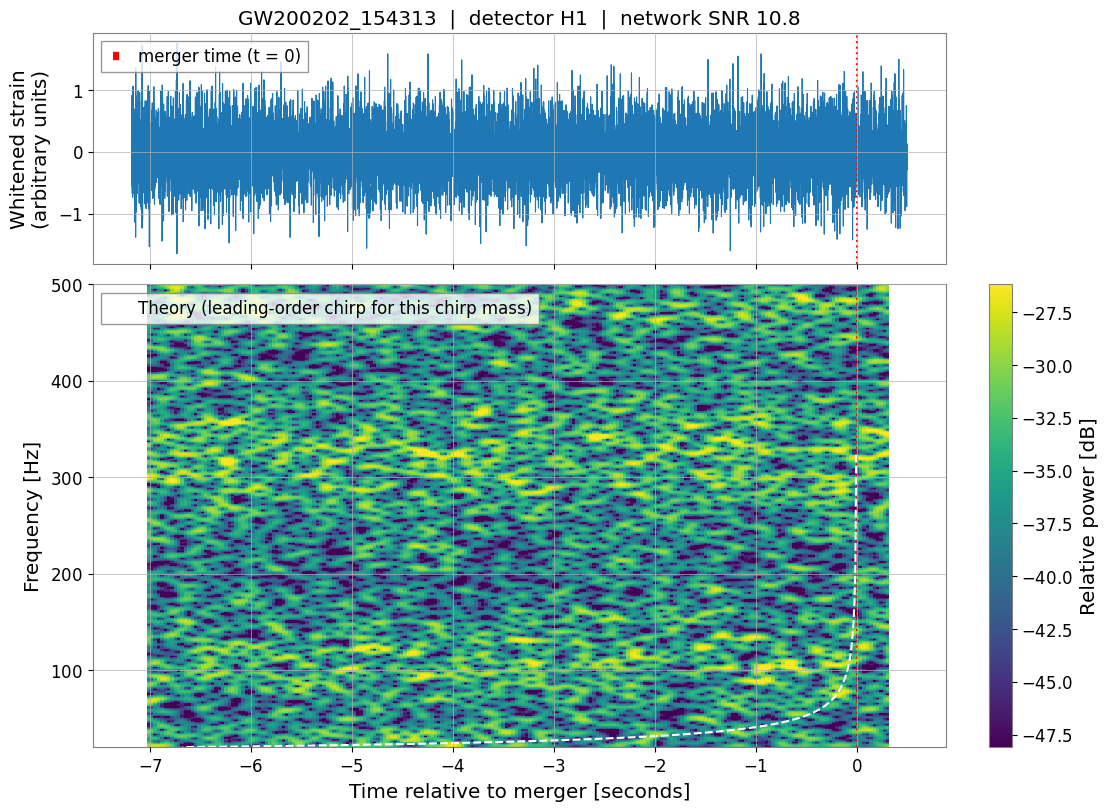


============== HOW TO READ THIS SPECTROGRAM (simple guide) ==============
AXES   Horizontal = time (0 = merger; negative = before).
       Vertical   = frequency (pitch). Colour = loudness (brighter = more power).

1) FIND THE CHIRP TRACK
   Look for a bright curved line that starts low on the left and sweeps UP and to
   the right, ending near t = 0. That curve IS the gravitational-wave signal.

2) WHAT THE SHAPE TELLS YOU
   - Steep and short (a quick sweep)   -> heavy system (black holes).
   - Long, gentle, slowly rising curve -> light system (neutron stars).
   - After t = 0 the track fades quickly: the merged object has settled down.

3) THE WHITE DASHED LINE (theory)
   It is the predicted chirp for chirp mass 8.1 solar masses (as seen
   by the detector). If the bright track follows it, the data agree with general
   relativity. Near t = 0 they separate: the formula only covers the inspiral.

4) THINGS THAT ARE NOT THE SIGNAL
   - Vertical bright streaks: instrument glitches (

In [10]:
# ============================================================================
# CELL 10 — SPECTROGRAM (frequency versus time)
# ============================================================================
# PHYSICAL PURPOSE
#   A spectrogram shows WHICH frequencies are present at WHICH time. A compact
#   binary merger draws a characteristic rising curve (the "chirp track"),
#   whose shape encodes the chirp mass of the system.

# ---- 10.1 Prepare the data and a time axis relative to the merger ----------------------------
# Cleaned strain values and their sample rate.
x = signal_zoom.value
fs = signal_zoom.sample_rate.value
# Start time of the clip relative to the merger (a NEGATIVE number, seconds).
start_rel = signal_zoom.t0.value - gps_merger
# Time of every sample relative to the merger (t = 0 is the merger).
time_axis = start_rel + np.arange(len(x)) / fs

# ---- 10.2 Choose the analysis window length ------------------------------------------------------
# Short windows resolve TIME well (fast chirps); long windows resolve FREQUENCY
# well (slow chirps). We pick ~1/20 of the in-band duration, between 0.0625 and 1 s.
window_seconds = float(np.clip(tau_band / 20.0, 0.0625, 1.0))
# Convert that window to a number of samples.
samples_per_window = int(round(window_seconds * fs))
# Consecutive windows overlap by 90% so the picture is smooth.
overlap_samples = int(0.9 * samples_per_window)

# ---- 10.3 Compute the spectrogram -------------------------------------------------------------------
# freqs: frequency of each row; seg_times: centre time of each column;
# power: signal power in each (frequency, time) cell.
# nfft = 4x window: zero-padding that makes the picture smoother (it does not
# improve the true resolution).
freqs, seg_times, power = spectrogram(x, fs=fs, window="hann",
                                      nperseg=samples_per_window,
                                      noverlap=overlap_samples,
                                      nfft=4 * samples_per_window,
                                      scaling="density", mode="psd")

# Keep only the rows inside our frequency band.
band_mask = (freqs >= BAND_LOW_HZ) & (freqs <= BAND_HIGH_HZ)
# Convert power to decibels (dB): a log scale that shows faint features.
power_db = 10.0 * np.log10(power[band_mask, :] + 1e-30)
# Shift the spectrogram's times so that 0 = merger.
times_rel = seg_times + time_axis[0]
# Colour limits: ignore the faintest 5% and brightest 0.3% so one glitch doesn't wash out the picture.
color_min = np.percentile(power_db, 5)
color_max = np.percentile(power_db, 99.7)

# ---- 10.4 Plot: top = waveform, bottom = spectrogram ---------------------------------------------------
fig, (ax_wave, ax_spec) = plt.subplots(2, 1, figsize=(11, 8), sharex=True,
                                       gridspec_kw={"height_ratios": [1, 2]},
                                       constrained_layout=True)

# Top panel: the cleaned waveform.
ax_wave.plot(time_axis, x, lw=0.8, color="tab:blue")
ax_wave.axvline(0, color="red", ls=":", label="merger time (t = 0)")
ax_wave.set_ylabel("Whitened strain\n(arbitrary units)")
ax_wave.set_title(f"{event_name}  |  detector {detector_used}  |  network SNR {fmt(network_snr)}")
ax_wave.legend(loc="upper left")

# Bottom panel: the spectrogram as a coloured map.
mesh = ax_spec.pcolormesh(times_rel, freqs[band_mask], power_db, shading="auto",
                          cmap="viridis", vmin=color_min, vmax=color_max)
ax_spec.axvline(0, color="red", ls=":")
ax_spec.set_xlabel("Time relative to merger [seconds]")
ax_spec.set_ylabel("Frequency [Hz]")
fig.colorbar(mesh, ax=ax_spec, label="Relative power [dB]")

# ---- 10.5 Overlay the theoretical chirp --------------------------------------------------------------------
if SHOW_THEORY_CHIRP:
    # Seconds-before-merger values to evaluate (avoid exactly 0: formula diverges).
    tau_values = np.linspace(0.004, -time_axis[0], 800)
    # Predicted frequency at each of those times.
    f_theory = chirp_frequency(tau_values, mc_detector)
    # Keep only points inside the plotted band.
    in_band = (f_theory >= BAND_LOW_HZ) & (f_theory <= BAND_HIGH_HZ)
    # Draw: time = -tau (before the merger), frequency = prediction.
    ax_spec.plot(-tau_values[in_band], f_theory[in_band], "w--", lw=1.5,
                 label="Theory (leading-order chirp for this chirp mass)")
    ax_spec.legend(loc="upper left")

plt.show()

# ---- 10.6 Printed guide -------------------------------------------------------------------------------------
print(f"""
============== HOW TO READ THIS SPECTROGRAM (simple guide) ==============
AXES   Horizontal = time (0 = merger; negative = before).
       Vertical   = frequency (pitch). Colour = loudness (brighter = more power).

1) FIND THE CHIRP TRACK
   Look for a bright curved line that starts low on the left and sweeps UP and to
   the right, ending near t = 0. That curve IS the gravitational-wave signal.

2) WHAT THE SHAPE TELLS YOU
   - Steep and short (a quick sweep)   -> heavy system (black holes).
   - Long, gentle, slowly rising curve -> light system (neutron stars).
   - After t = 0 the track fades quickly: the merged object has settled down.

3) THE WHITE DASHED LINE (theory)
   It is the predicted chirp for chirp mass {mc_detector:.1f} solar masses (as seen
   by the detector). If the bright track follows it, the data agree with general
   relativity. Near t = 0 they separate: the formula only covers the inspiral.

4) THINGS THAT ARE NOT THE SIGNAL
   - Vertical bright streaks: instrument glitches (very short bursts of noise).
   - Horizontal lines: steady noise at fixed frequencies (e.g. electrical hum).
   - Uniform speckle: ordinary detector noise.

5) QUICK SANITY CHECK
   Network SNR = {fmt(network_snr)}. Above ~15 the track is usually obvious; near
   10 it may be faint; below 8 it can be invisible. Try the Q-transform below.
=========================================================================
""")

#11.Q-transform

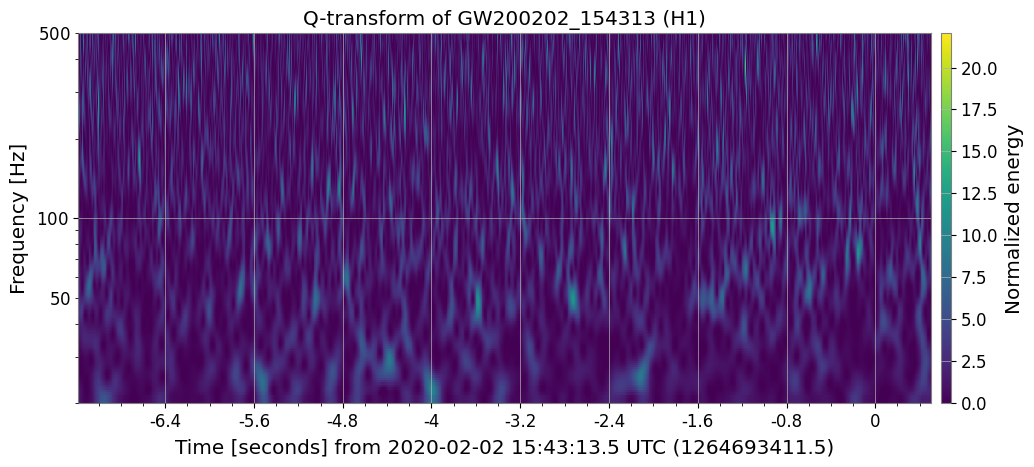

Read it like Cell 10: look for a bright arc rising toward t = 0.
Brighter colour = energy far above the noise (signal).


In [11]:
# ============================================================================
# CELL 11 — Q-TRANSFORM SPECTROGRAM  (LIGO's standard "chirp picture")
# ============================================================================
# PHYSICAL PURPOSE
#   The Q-transform is a spectrogram whose time/frequency resolution adapts to
#   the signal. It is the standard way LIGO scientists show chirps, and it often
#   shows faint tracks more clearly than the plain spectrogram in Cell 10.
#   It whitens the raw data itself, so we give it the ORIGINAL strain.

if MAKE_Q_TRANSFORM:
    try:
        # Compute the Q-transform only inside our window (outseg = output segment).
        # frange: frequency range to map. qrange: allowed 'quality factors'; low Q
        # = good time resolution, high Q = good frequency resolution.
        q_map = strain.q_transform(outseg=(gps_merger - clip_before, gps_merger + clip_after),
                                   frange=(BAND_LOW_HZ, BAND_HIGH_HZ),
                                   qrange=(4, 64))

        # Draw it. vmin=0 sets the darkest colour to zero energy.
        q_plot = q_map.plot(figsize=(11, 5), vmin=0)
        # Grab the plot's axes so we can decorate them.
        q_axis = q_plot.gca()
        # Make the time axis read "seconds relative to the merger".
        q_axis.set_epoch(gps_merger)
        # Log frequency axis spreads out the low frequencies where the chirp begins.
        q_axis.set_yscale("log")
        q_axis.set_ylim(BAND_LOW_HZ, BAND_HIGH_HZ)
        q_axis.set_ylabel("Frequency [Hz]")
        q_axis.set_title(f"Q-transform of {event_name} ({detector_used})")
        # Colour bar: 'normalized energy' = signal energy divided by typical noise
        # energy (~1 means just noise; much larger means signal).
        q_axis.colorbar(label="Normalized energy")
        plt.show()

        print("Read it like Cell 10: look for a bright arc rising toward t = 0.\n"
              "Brighter colour = energy far above the noise (signal).")
    except Exception as error:
        # If anything fails, say so but let the rest of the notebook continue.
        print(f"Q-transform skipped: {error}")
else:
    print("Q-transform disabled (MAKE_Q_TRANSFORM = False in Cell 3).")

#12.Final analysis

In [12]:
# ============================================================================
# CELL 12 — FINAL ANALYSIS: WHAT DID WE JUST OBSERVE?
# ============================================================================
# PHYSICAL PURPOSE
#   Answer the three scientific questions using the measured masses and the
#   shape of the signal.

# Classify the source from its component masses (function defined in Cell 4).
source_label, source_reason = classify_source(m1_src, m2_src, final_mass)

# Describe the chirp length qualitatively from the time spent in band.
if tau_band < 2.0:
    chirp_length = "very short chirp (heavy system; mostly merger + ringdown is visible)"
elif tau_band < 20.0:
    chirp_length = "short chirp (several seconds of inspiral)"
else:
    chirp_length = "long chirp (light system; many seconds of inspiral)"

print("=" * 72)
print(f"ANALYSIS REPORT — {event_name}")
print("=" * 72)

# ---- Question 1 ------------------------------------------------------------------
print("\n1) WHICH TYPE OF SIGNAL?")
print("   -> A TRANSIENT 'CHIRP' from a COMPACT BINARY COALESCENCE (CBC).")
print(f"   Subtype: {chirp_length}; ~{tau_band:.2f} s above {BAND_LOW_HZ:.0f} Hz.")
print("   Why: the frequency rises quickly toward a peak and then vanishes: the")
print("   signature of two compact objects spiralling together and merging.")
print("   LIGO searches for four signal families. Only the first has been")
print("   confirmed in LIGO data so far:")
print("     * Compact-binary chirps ........ detected (hundreds of events)  <- THIS ONE")
print("     * Unmodelled bursts (supernovae) not yet detected")
print("     * Continuous waves (spinning neutron stars) not yet detected")
print("     * Stochastic background ........ not yet detected")

# ---- Question 2 ------------------------------------------------------------------
print("\n2) WHICH TYPE OF SOURCE?")
print(f"   -> {source_label}")
print(f"   Masses: {fmt(m1_src)} + {fmt(m2_src)} solar masses "
      f"(chirp mass {mc_source:.1f}); remnant: {fmt(final_mass)} solar masses.")
print(f"   Reasoning: {source_reason}")
if radiated_mass is not None:
    print(f"   Energy: about {radiated_mass:.1f} solar masses vanished into gravitational waves (E = mc^2).")
print("   Caution: this rule uses median catalog masses. Official classifications")
print("   come from full statistical analyses by the LIGO-Virgo-KAGRA collaboration.")

# ---- Question 3 ------------------------------------------------------------------
print("\n3) NAME OF THE SOURCE")
print(f"   -> {event_name}")
print("   Naming rule: 'GW' + year/month/day of detection (YYMMDD, in UTC), sometimes")
print("   followed by the time of day (_hhmmss).")
print(f"   Detected (UTC): {utc_time}")
print(f"   Catalog       : {catalog_label}")
if distance_mpc is not None:
    print(f"   Distance      : ~{distance_mpc:.0f} Mpc (~{distance_mpc * 3.26:.0f} million "
          f"light-years): the waves travelled that long before reaching Earth.")

# ---- Data quality note --------------------------------------------------------------
print("\nDATA USED")
print(f"   Detector {detector_used}, window {clip_before:.1f} s before to {clip_after:.1f} s after merger,")
print(f"   band {BAND_LOW_HZ:.0f}-{BAND_HIGH_HZ:.0f} Hz.  Event metadata: {info.get('jsonurl', 'GWOSC event API')}")
print("   Learn more: https://gwosc.org  (event portal, tutorials, data)")
print("\nRun the notebook again for a NEW source!")
print("=" * 72)

ANALYSIS REPORT — GW200202_154313

1) WHICH TYPE OF SIGNAL?
   -> A TRANSIENT 'CHIRP' from a COMPACT BINARY COALESCENCE (CBC).
   Subtype: short chirp (several seconds of inspiral); ~6.68 s above 20 Hz.
   Why: the frequency rises quickly toward a peak and then vanishes: the
   signature of two compact objects spiralling together and merging.
   LIGO searches for four signal families. Only the first has been
   confirmed in LIGO data so far:
     * Compact-binary chirps ........ detected (hundreds of events)  <- THIS ONE
     * Unmodelled bursts (supernovae) not yet detected
     * Continuous waves (spinning neutron stars) not yet detected
     * Stochastic background ........ not yet detected

2) WHICH TYPE OF SOURCE?
   -> Binary black hole (BBH) merger
   Masses: 10.1 + 7.3 solar masses (chirp mass 7.5); remnant: 16.8 solar masses.
   Reasoning: Both objects are heavier than ~5 solar masses, so both are black holes.
   Energy: about 0.6 solar masses vanished into gravitational waves

#13.GIF of the source and its impact

Rendering 185 frames (this can take ~1 minute)...
Saved: GW200202_154313_impact.gif


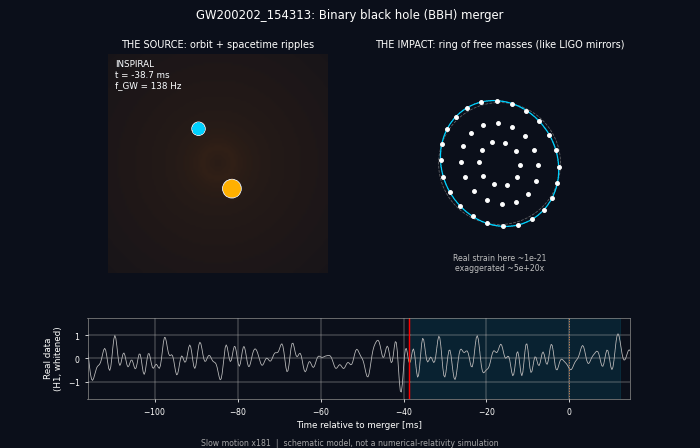


=================== HOW TO READ THE GIF (simple guide) ===================
LEFT: THE SOURCE
  - Orange and cyan dots = the two objects (10.1 and 7.3 solar masses).
    They circle faster and faster as they spiral in: this is the 'chirp'.
  - Orange/cyan background waves = ripples of spacetime travelling outwards.
  - When the dots touch they merge into one white object that 'rings' briefly
    (the ringdown) and then goes quiet.

RIGHT: THE IMPACT
  - Each dot is a free-floating mass, like a LIGO mirror. The dashed circle shows
    where they would sit with no wave.
  - Face-on (INCLINATION_DEG = 0) the squeeze rotates; edge-on (90) the ring just
    alternates between 'tall and thin' and 'short and wide'.
  - Faster wiggles = higher GW frequency; bigger wiggles = stronger wave.

BOTTOM: THE REAL DATA
  - Grey line = the cleaned signal measured by H1. The red cursor shows
    the moment being animated. At low SNR the data look like noise; the signal
    is only recovered statistically

In [13]:
# ============================================================================
# CELL 13 — GIF: THE SOURCE AND ITS IMPACT ON SPACETIME
# ============================================================================
# PHYSICAL PURPOSE
#   Make an animated GIF with three linked views of the event you analysed:
#     (top left)  THE SOURCE: two compact objects spiral together, merge and
#                 settle into one object, sending out ripples of spacetime.
#     (top right) THE IMPACT: a ring of free-floating test masses (like the
#                 mirrors of LIGO). When a gravitational wave passes, the ring is
#                 alternately squeezed and stretched. This is exactly what a
#                 detector measures.
#     (bottom)    THE REAL DATA from the detector, with a red cursor showing which
#                 moment is currently animated.
#   The motion is SLOW MOTION and the squeeze is hugely EXAGGERATED (the real
#   effect is ~1e-21, far too small to see).
#   IMPORTANT: run Cells 1-12 first. This cell re-uses their variables.
#   HONESTY NOTE: this is a schematic model (leading-order inspiral formulas +
#   a simple damped "ringdown"), not a full numerical-relativity simulation.

# ---- 13.0 Extra tools needed only for animation -------------------------------
# FuncAnimation: calls an "update" function once per frame to build an animation.
# PillowWriter : saves those frames as an animated .gif file.
from matplotlib.animation import FuncAnimation, PillowWriter
# Circle: a round shape drawn in data coordinates (we use it for the objects).
from matplotlib.patches import Circle
# LinearSegmentedColormap: lets us design our own colour scale for the ripples.
from matplotlib.colors import LinearSegmentedColormap
# Image: shows the finished GIF inside the notebook.
from IPython.display import Image

# ---- 13.1 SETTINGS (EDIT ME) ----------------------------------------------------
# Viewing angle of the binary. 0 = looking straight down on the orbit ("face-on":
# the ring rotates smoothly). 90 = edge-on (the ring just squeezes along one
# direction then the other, like a real LIGO arm pair).
INCLINATION_DEG = 0.0
# How strongly the ring is deformed at the loudest moment (0.5 -> about +-25% of its
# size). Pure visual exaggeration; the real strain is ~1e-21.
RING_STRETCH = 0.5
# Frames per second of the GIF (higher = smoother but plays faster).
GIF_FPS = 20
# Resolution of the GIF in dots per inch (higher = sharper but a bigger file).
GIF_DPI = 70
# How many animation frames show the INSPIRAL (before the merger).
N_INSPIRAL_FRAMES = 140
# How many animation frames show the RINGDOWN (after the merger).
N_POST_FRAMES = 45
# Frames drawn per orbit at the very end. 6 = smooth; lower = faster/coarser.
FRAMES_PER_END_ORBIT = 6
# Resolution of the ripple map (GRID_POINTS x GRID_POINTS pixels). Lower = faster.
GRID_POINTS = 110
# Assumed radius of a neutron star in metres (typical value ~12 km).
NS_RADIUS_M = 12000.0
# Name of the GIF file that will be saved next to this notebook.
GIF_FILENAME = f"{event_name}_impact.gif"

# ---- 13.2 Physical constants -----------------------------------------------------
# Speed of light in metres per second.
C_LIGHT = 299792458.0
# G * (1 solar mass) / c^2 expressed as a length in metres (~1.48 km).
G_MSUN_OVER_C2 = 1476.63
# Number of metres in one megaparsec.
MPC_IN_M = 3.0857e22

# ---- 13.3 Set up the physical model of the source -------------------------------
# Total mass as the DETECTOR sees it (cosmic expansion makes it look (1+z) heavier).
total_mass_det = total_mass * (1.0 + redshift)
# Total mass converted to seconds (G*M/c^3). "M" below means this time unit.
T_tot = total_mass_det * T_SUN
# Chirp mass converted to seconds (used in the phase formula).
T_chirp = mc_detector * T_SUN


def radius_in_M(mass_src):
    # Size of one object, measured in units of the total mass M (G = c = 1).
    # Neutron star: fixed physical radius (about 12 km) divided by G*M/c^2.
    if mass_src <= NS_MAX_MASS:
        return NS_RADIUS_M / (G_MSUN_OVER_C2 * total_mass)
    # Black hole: the horizon radius is 2*G*m/c^2, i.e. 2*m/M in units of M.
    return 2.0 * mass_src / total_mass


# Sizes of the two objects (units of M).
R1 = radius_in_M(m1_src)
R2 = radius_in_M(m2_src)
# Separation at which the two objects touch (units of M).
a_contact = R1 + R2
# GW frequency when they touch, from Kepler's law: f = a^(-3/2) / (pi * G*M/c^3).
f_contact = a_contact ** (-1.5) / (np.pi * T_tot)
# Orbital frequency at that moment (the GW frequency is twice the orbital one).
f_orb_contact = f_contact / 2.0
# Seconds before coalescence at which that frequency is reached (Cell 4 function).
tau_contact = seconds_in_band(mc_detector, f_contact)

# --- Remnant (the single object after the merger) ---
# Mass of the remnant in the source frame (catalog value, or 95% of the total if missing).
remnant_mass_src = final_mass if final_mass is not None else 0.95 * total_mass
# Remnant mass in seconds, as seen by the detector.
T_final = remnant_mass_src * (1.0 + redshift) * T_SUN
# Ringdown frequency of a NON-spinning black hole: f = 0.3737 / (2*pi*G*M/c^3).
# (Real remnants spin, which makes the true frequency higher: schematic only.)
f_ring = 0.3737 / (2.0 * np.pi * T_final)
# Ringdown damping time of a non-spinning black hole: tau = (G*M/c^3) / 0.0890.
tau_damp = T_final / 0.0890
# Radius of the remnant horizon in units of M.
R_final = 2.0 * remnant_mass_src / total_mass


def model_wave(t_seconds):
    # Schematic gravitational waveform at time t (0 = the objects touch).
    # Returns (relative amplitude, GW phase in radians, GW frequency in Hz).
    # Works on single numbers AND on whole arrays at once.
    t = np.asarray(t_seconds, dtype=float)

    # --- Inspiral (t < 0) ---
    # Time left until coalescence; never below tau_contact (avoids invalid maths).
    tau = np.maximum(tau_contact - t, tau_contact)
    # Predicted GW frequency (Cell 4 function).
    f_ins = chirp_frequency(tau, mc_detector)
    # Amplitude grows as f^(2/3); scaled so it equals 1 at contact.
    amp_ins = (f_ins / f_contact) ** (2.0 / 3.0)
    # GW phase from integrating the frequency; shifted so it is 0 at contact.
    phase_ins = 2.0 * (tau_contact / (5.0 * T_chirp)) ** 0.625 \
                - 2.0 * (tau / (5.0 * T_chirp)) ** 0.625

    # --- Ringdown (t >= 0) ---
    # Only times after contact count here (negative times are clipped to 0).
    t_after = np.maximum(t, 0.0)
    # Exponentially fading amplitude, starting at 1.
    amp_ring = np.exp(-t_after / tau_damp)
    # Steady oscillation at the ringdown frequency.
    phase_ring = 2.0 * np.pi * f_ring * t_after

    # Pick the inspiral formulas before contact and the ringdown formulas after.
    before = t < 0
    amplitude = np.where(before, amp_ins, amp_ring)
    phase = np.where(before, phase_ins, phase_ring)
    frequency = np.where(before, f_ins, f_ring)
    return amplitude, phase, frequency


# ---- 13.4 Build the list of animation moments (time of every frame) --------------
# Real time between frames: fine enough to show f_GW at contact in 'FRAMES_PER_END_ORBIT' steps.
dt_frame = 1.0 / (FRAMES_PER_END_ORBIT * f_orb_contact)
# Frame times in seconds: negative = before contact, 0 = contact, positive = after.
t_frames = (np.arange(N_INSPIRAL_FRAMES + N_POST_FRAMES) - N_INSPIRAL_FRAMES) * dt_frame
# Waveform amplitude, phase and frequency at the centre for every frame.
amp_f, phase_f, freq_f = model_wave(t_frames)

# ---- 13.5 Orbit geometry for every frame ---------------------------------------------
# cos(inclination): squashes the orbit's vertical size when seen at an angle.
cos_i = np.cos(np.radians(INCLINATION_DEG))
# Orbital angle = half the GW phase (the wave goes round twice per orbit).
theta = phase_f / 2.0
# Separation in units of M from Kepler: a = (pi * f * G*M/c^3)^(-2/3).
separation = (np.pi * freq_f * T_tot) ** (-2.0 / 3.0)
# Before contact the separation can't be smaller than touching; after, it's unused.
separation = np.where(t_frames < 0, np.maximum(separation, a_contact), a_contact)
# Distances from the centre of mass: the HEAVIER object sits closer to the centre.
r1 = separation * (m2_src / total_mass)
r2 = separation * (m1_src / total_mass)
# Screen positions of object 1 (x to the right, y up; y squashed if tilted).
x1, y1 = r1 * np.cos(theta), r1 * np.sin(theta) * cos_i
# Object 2 is always on the opposite side of the centre.
x2, y2 = -r2 * np.cos(theta), -r2 * np.sin(theta) * cos_i

# ---- 13.6 Size of the source panel and the ripple map --------------------------------
# Wavelength of the final inspiral wave, in units of M (wavelength = c / f).
wavelength_end = 1.0 / (f_contact * T_tot)
# Half-width of the panel: big enough for the first orbit AND about one wavelength.
L = float(max(1.6 * separation[0], 1.2 * wavelength_end))
# Pixel coordinates of the ripple map.
grid_axis = np.linspace(-L, L, GRID_POINTS)
# 2-D arrays with the x and y position of every pixel.
grid_x, grid_y = np.meshgrid(grid_axis, grid_axis)
# Distance of every pixel from the source (units of M).
grid_r = np.hypot(grid_x, grid_y)
# Light-travel time from the source to each pixel, in seconds (distance * G*M/c^3).
retard_seconds = grid_r * T_tot
# Ripples fade with distance (gentler than the real 1/r so they stay visible).
fade = (a_contact / np.maximum(grid_r, a_contact)) ** 0.6

# ---- 13.7 How big is the REAL effect on Earth? ------------------------------------------
# Real strain amplitude at Earth (face-on, at contact):
#     h = 4 * c * (G*Mc/c^3)^(5/3) * (pi*f)^(2/3) / distance
if distance_mpc is not None:
    h_earth = 4.0 * C_LIGHT * T_chirp ** (5.0 / 3.0) * (np.pi * f_contact) ** (2.0 / 3.0) \
              / (distance_mpc * MPC_IN_M)
    # Change in a 4 km LIGO arm: about h * L / 2.
    delta_arm = 0.5 * h_earth * 4000.0
    # How many times larger the ring deformation is than reality.
    exaggeration = RING_STRETCH / h_earth
    ring_caption = f"Real strain here ~{h_earth:.0e}\nexaggerated ~{exaggeration:.0e}x"
else:
    h_earth = delta_arm = exaggeration = None
    ring_caption = "Strain exaggerated for visibility"

# ---- 13.8 The real detector data for the bottom strip ------------------------------------
# Sample rate and time axis of the cleaned data from Cell 8 (milliseconds vs merger).
data_fs = signal_zoom.sample_rate.value
data_t_ms = (signal_zoom.t0.value - gps_merger + np.arange(len(signal_zoom)) / data_fs) * 1000.0
# The cleaned strain values themselves.
data_y = signal_zoom.value
# Start and end of the animated window in milliseconds.
view_start_ms = t_frames[0] * 1000.0
view_end_ms = t_frames[-1] * 1000.0
# Show a little more data before the animated part so you see the context.
strip_before_ms = min(clip_before * 1000.0, 3.0 * abs(view_start_ms))
strip_after_ms = min(clip_after * 1000.0, 1.2 * view_end_ms)
# Choose the y-range from the data actually visible in that window.
visible = (data_t_ms >= -strip_before_ms) & (data_t_ms <= strip_after_ms)
y_limit = 1.2 * np.max(np.abs(data_y[visible])) if visible.any() else 1.0

# ---- 13.9 Draw the (empty) figure and create every moving object ------------------------
# Colours: a dark "space" background with orange/cyan accents.
BG = "#0b0f1a"
# Figure with a top row (two squares) and a bottom row (the real data).
fig = plt.figure(figsize=(10, 6.4), facecolor=BG)
layout = fig.add_gridspec(2, 2, height_ratios=[3, 1.1], hspace=0.30, wspace=0.08)
ax_src = fig.add_subplot(layout[0, 0])     # top-left: source + ripples
ax_ring = fig.add_subplot(layout[0, 1])    # top-right: ring of test masses
ax_strip = fig.add_subplot(layout[1, :])   # bottom: real detector data

# ---- Source panel ----
ax_src.set_facecolor(BG)
ax_src.set_xlim(-L, L)
ax_src.set_ylim(-L, L)
ax_src.set_aspect("equal")        # equal scaling so circles stay circles
ax_src.axis("off")                # hide ticks/frame
ax_src.set_title("THE SOURCE: orbit + spacetime ripples", color="white", fontsize=10)
# Ripple colour scale: orange (+), dark (0), cyan (-); the middle matches the background.
ripple_cmap = LinearSegmentedColormap.from_list("ripple", ["#ff7a00", BG, "#00c8ff"])
# The ripple image (filled with zeros now; updated every frame).
ripple_img = ax_src.imshow(np.zeros_like(grid_x), extent=(-L, L, -L, L), origin="lower",
                           cmap=ripple_cmap, vmin=-1, vmax=1, interpolation="bilinear", zorder=1)
# The two orbiting objects (centres set later).
body1 = Circle((0, 0), R1, facecolor="#ffb000", edgecolor="white", lw=0.8, zorder=4)
body2 = Circle((0, 0), R2, facecolor="#00d1ff", edgecolor="white", lw=0.8, zorder=4)
# The merged remnant (hidden until the merger).
remnant = Circle((0, 0), R_final, facecolor="#f5f5f5", edgecolor="#ff7a00", lw=1.5, zorder=5)
# Put the three shapes on the axes.
ax_src.add_patch(body1)
ax_src.add_patch(body2)
ax_src.add_patch(remnant)
remnant.set_visible(False)
# Thin trails that follow each object.
trail1, = ax_src.plot([], [], color="#ffb000", lw=1, alpha=0.7, zorder=3)
trail2, = ax_src.plot([], [], color="#00d1ff", lw=1, alpha=0.7, zorder=3)
# Text readout (stage, time, frequency) in the corner.
info_text = ax_src.text(0.03, 0.97, "", transform=ax_src.transAxes, color="white",
                        fontsize=9, va="top", zorder=6)

# ---- Ring (impact) panel ----
ax_ring.set_facecolor(BG)
ax_ring.set_xlim(-1.8, 1.8)
ax_ring.set_ylim(-1.8, 1.8)
ax_ring.set_aspect("equal")
ax_ring.axis("off")
ax_ring.set_title("THE IMPACT: ring of free masses (like LIGO mirrors)", color="white", fontsize=10)
# Three concentric rings of test masses: radius and number of dots in each.
ring_radii = [0.35, 0.65, 1.0]
ring_counts = [10, 16, 24]
# Collect the undisturbed x and y position of every dot.
base_x, base_y = [], []
for radius, count in zip(ring_radii, ring_counts):
    angles = np.linspace(0, 2 * np.pi, count, endpoint=False)
    base_x.extend(radius * np.cos(angles))
    base_y.extend(radius * np.sin(angles))
base_x, base_y = np.array(base_x), np.array(base_y)
# Smooth outline of the outer ring.
outline_angles = np.linspace(0, 2 * np.pi, 200)
out_x, out_y = np.cos(outline_angles), np.sin(outline_angles)
# Dashed grey circle = where the ring would be WITHOUT any wave (reference).
ax_ring.plot(out_x, out_y, "--", color="0.4", lw=0.8)
# The deformed outline (updated every frame).
ring_line, = ax_ring.plot([], [], color="#00d1ff", lw=1.3)
# The test masses themselves.
ring_dots = ax_ring.scatter(base_x, base_y, s=16, c="white", zorder=3)
# Caption with the real vs exaggerated strain.
ax_ring.text(0.5, 0.0, ring_caption, transform=ax_ring.transAxes, color="0.75",
             fontsize=8, ha="center", va="bottom")

# ---- Real-data strip ----
ax_strip.set_facecolor(BG)
# The real cleaned detector data (milliseconds relative to the merger).
ax_strip.plot(data_t_ms, data_y, color="0.75", lw=0.8)
# Light band marking the part of the data that is being animated.
ax_strip.axvspan(view_start_ms, view_end_ms, color="#00d1ff", alpha=0.10)
# Dotted orange line at the catalog merger time (t = 0).
ax_strip.axvline(0, color="#ff7a00", ls=":", lw=1)
# The moving red cursor.
cursor = ax_strip.axvline(view_start_ms, color="red", lw=1.5)
ax_strip.set_xlim(-strip_before_ms, strip_after_ms)
ax_strip.set_ylim(-y_limit, y_limit)
ax_strip.set_xlabel("Time relative to merger [ms]", color="white", fontsize=9)
ax_strip.set_ylabel(f"Real data\n({detector_used}, whitened)", color="white", fontsize=9)
# White tick labels and frame for the dark background.
ax_strip.tick_params(colors="white", labelsize=8)
for spine in ax_strip.spines.values():
    spine.set_color("0.5")

# Slow-motion factor: GIF seconds per frame divided by real seconds per frame.
slow_motion = (1.0 / GIF_FPS) / dt_frame
fig.suptitle(f"{event_name}: {source_label}", color="white", fontsize=12)
fig.text(0.5, 0.005,
         f"Slow motion x{slow_motion:.0f}  |  schematic model, not a numerical-relativity simulation",
         ha="center", color="0.65", fontsize=8)

# How many past frames the orbit trails keep.
TRAIL_FRAMES = 40


def deform(px, py, h_plus, h_cross):
    # Moves points the way a passing gravitational wave moves free masses.
    # h_plus  squeezes one axis while stretching the other.
    # h_cross does the same along the diagonals.
    new_x = px + 0.5 * (h_plus * px + h_cross * py)
    new_y = py + 0.5 * (-h_plus * py + h_cross * px)
    return new_x, new_y


def update(i):
    # Called once per frame i: moves everything to its position at time t_frames[i].
    t_now = t_frames[i]

    # ---- 1) Spacetime ripples around the source ----
    # Each pixel sees the wave emitted EARLIER by the light-travel time to it.
    amp_r, phase_r, _ = model_wave(t_now - retard_seconds)
    # Ripple value = faded amplitude * cos(phase): orange = stretch, cyan = squeeze.
    ripple_img.set_data(fade * amp_r * np.cos(phase_r))

    # ---- 2) The objects ----
    if t_now < 0:
        # Inspiral: two separate objects.
        body1.set_visible(True)
        body2.set_visible(True)
        remnant.set_visible(False)
        body1.center = (x1[i], y1[i])
        body2.center = (x2[i], y2[i])
        # Trails: the last TRAIL_FRAMES positions.
        start = max(0, i - TRAIL_FRAMES)
        trail1.set_data(x1[start:i + 1], y1[start:i + 1])
        trail2.set_data(x2[start:i + 1], y2[start:i + 1])
        stage = "INSPIRAL"
    else:
        # After contact: one merged object that 'rings' (its radius wobbles).
        body1.set_visible(False)
        body2.set_visible(False)
        remnant.set_visible(True)
        remnant.radius = R_final * (1.0 + 0.12 * amp_f[i] * np.cos(phase_f[i]))
        trail1.set_data([], [])
        trail2.set_data([], [])
        stage = "MERGER" if i == N_INSPIRAL_FRAMES else "RINGDOWN"

    # ---- 3) The ring of test masses (what a detector 'feels') ----
    # Plus and cross polarisations seen at the chosen inclination.
    h_plus = RING_STRETCH * amp_f[i] * (1.0 + cos_i ** 2) / 2.0 * np.cos(phase_f[i])
    h_cross = RING_STRETCH * amp_f[i] * cos_i * np.sin(phase_f[i])
    # Move every dot and the outline accordingly.
    dot_x, dot_y = deform(base_x, base_y, h_plus, h_cross)
    ring_dots.set_offsets(np.column_stack([dot_x, dot_y]))
    line_x, line_y = deform(out_x, out_y, h_plus, h_cross)
    ring_line.set_data(line_x, line_y)

    # ---- 4) Cursor on the real data and the text readout ----
    cursor.set_xdata([t_now * 1000.0, t_now * 1000.0])
    info_text.set_text(f"{stage}\nt = {t_now * 1000:+.1f} ms\nf_GW = {freq_f[i]:.0f} Hz")


# ---- 13.10 Render the GIF and show it ---------------------------------------------------------
# Build the animation: 'update' is called for every frame index.
animation = FuncAnimation(fig, update, frames=len(t_frames),
                          interval=1000.0 / GIF_FPS, blit=False)
print(f"Rendering {len(t_frames)} frames (this can take ~1 minute)...")
# Save as an animated GIF that loops forever.
animation.save(GIF_FILENAME, writer=PillowWriter(fps=GIF_FPS), dpi=GIF_DPI)
# Close the figure so Jupyter doesn't also show a static copy.
plt.close(fig)
print(f"Saved: {GIF_FILENAME}")
# Display the GIF right here in the notebook.
display(Image(filename=GIF_FILENAME))

# ---- 13.11 Printed guide ---------------------------------------------------------------------------
print(f"""
=================== HOW TO READ THE GIF (simple guide) ===================
LEFT: THE SOURCE
  - Orange and cyan dots = the two objects ({fmt(m1_src)} and {fmt(m2_src)} solar masses).
    They circle faster and faster as they spiral in: this is the 'chirp'.
  - Orange/cyan background waves = ripples of spacetime travelling outwards.
  - When the dots touch they merge into one white object that 'rings' briefly
    (the ringdown) and then goes quiet.

RIGHT: THE IMPACT
  - Each dot is a free-floating mass, like a LIGO mirror. The dashed circle shows
    where they would sit with no wave.
  - Face-on (INCLINATION_DEG = 0) the squeeze rotates; edge-on (90) the ring just
    alternates between 'tall and thin' and 'short and wide'.
  - Faster wiggles = higher GW frequency; bigger wiggles = stronger wave.

BOTTOM: THE REAL DATA
  - Grey line = the cleaned signal measured by {detector_used}. The red cursor shows
    the moment being animated. At low SNR the data look like noise; the signal
    is only recovered statistically (see the spectrogram).

SCALE OF REALITY
  - Slow motion factor: x{slow_motion:.0f}.
  - GW frequency at contact (Newtonian estimate): ~{f_contact:.0f} Hz.""")
if h_earth is not None:
    print(f"  - Estimated strain at Earth: h ~ {h_earth:.1e}. A 4 km LIGO arm changes by only"
          f" ~{delta_arm:.0e} m,\n    a few hundred times smaller than a proton. The ring above is"
          f" exaggerated ~{exaggeration:.0e}x.")
print("""
LIMITS OF THIS MODEL
  - Inspiral: leading-order (Newtonian) formulas. Merger/ringdown: a simple damped
    oscillation for a non-spinning black hole. Real events need numerical relativity.
  - Time 0 here is the moment the objects touch; the catalog's merger time (the
    dotted line in the bottom panel) can differ by a few milliseconds.
==========================================================================
""")

#14.Save and download everything to your computer

In [14]:
# ============================================================================
# CELL 14 — SAVE EVERYTHING AND DOWNLOAD IT TO YOUR COMPUTER
# ============================================================================
# PHYSICAL PURPOSE
#   Preserve the complete scientific record of this analysis so you can reuse it
#   outside the notebook:
#     * the two audio files (.wav)             from Cell 9
#     * the source-and-impact animation (.gif) from Cell 13
#     * the spectrogram figure (.png)          re-drawn here (it was only displayed)
#     * the Q-transform figure (.png)          from Cell 11 (if it was made)
#     * the cleaned detector signal (.csv)     so you can re-analyse it yourself
#     * the analysis report (.txt)             the three answers + event card
#     * the event parameters (.json)           machine-readable numbers
#   Everything is placed in ONE folder, packed into ONE .zip file, and then
#   delivered to your computer (method depends on where the notebook runs).
#
# HOW TO USE
#   Run this cell RIGHT AFTER Cell 13, in the same run. If you re-run Cell 5 first,
#   a NEW event is selected and the variables of the old event are replaced.
#   Cloud notebooks (Colab etc.) delete their files when the session ends, so
#   download before closing the tab.

# ---- 14.0 Tools needed only for saving -----------------------------------------
# sys: lets us ask Python which modules are loaded (used to detect Google Colab).
import sys
# shutil: copies files and folders.
import shutil
# zipfile: packs many files into one .zip archive.
import zipfile
# json: writes dictionaries to a text file other programs can read.
import json
# FileLink: creates a clickable download link inside the notebook.
from IPython.display import FileLink

# ---- 14.1 SETTINGS (EDIT ME) ------------------------------------------------------
# Name of the folder (created next to this notebook) that will hold all results.
# Using the event name means different events never overwrite each other.
OUTPUT_FOLDER = f"{event_name}_results"
# OPTIONAL: a folder on YOUR computer where an extra copy should be placed.
# Works when Jupyter runs on your own computer. Leave as None to skip. Examples:
#   LOCAL_COPY_FOLDER = "~/Documents/GW_results"                  (Mac / Linux)
#   LOCAL_COPY_FOLDER = r"C:\Users\YourName\Documents\GW_results" (Windows)
LOCAL_COPY_FOLDER = None
# True = in Google Colab, start the browser download of the .zip automatically.
AUTO_DOWNLOAD_IN_COLAB = True
# True = also save the cleaned detector signal as a .csv table.
INCLUDE_CLEAN_DATA_CSV = True
# Sharpness of the saved pictures (dots per inch). 200 is good for reports.
FIGURE_DPI = 200

# ---- 14.2 Create the (empty) results folder -----------------------------------------
# exist_ok=True means "don't complain if the folder already exists".
os.makedirs(OUTPUT_FOLDER, exist_ok=True)
# Running list of the file names we manage to save (used for the zip and the summary).
saved_files = []


def copy_into_folder(source_path):
    # Copies one existing file into the results folder.
    # If the file is missing (e.g. you skipped a cell) we explain instead of crashing.
    if source_path is None or not os.path.exists(source_path):
        print(f"  (skipped: file not found: {source_path}. Did you run the earlier cell?)")
        return
    # Keep only the file's own name (drop any folder part).
    base_name = os.path.basename(source_path)
    # Full destination path inside the results folder.
    destination = os.path.join(OUTPUT_FOLDER, base_name)
    # copy2 copies the file and keeps its timestamps.
    shutil.copy2(source_path, destination)
    # Remember it for the zip file and the final summary.
    saved_files.append(base_name)
    print(f"  ✓ {base_name}")


# ---- 14.3 Copy the audio files (made in Cell 9) and the GIF (made in Cell 13) ----------
print("Collecting audio and animation files ...")
# globals().get(name) returns None instead of an error if the variable doesn't exist.
copy_into_folder(globals().get("file_real"))
copy_into_folder(globals().get("file_fast"))
copy_into_folder(globals().get("GIF_FILENAME"))

# ---- 14.4 Re-draw and save the spectrogram figure (Cell 10 only displayed it) ----------
print("Saving the spectrogram figure ...")
try:
    # Same layout as Cell 10: top = waveform, bottom = spectrogram.
    fig_s, (ax_w, ax_s) = plt.subplots(2, 1, figsize=(11, 8), sharex=True,
                                       gridspec_kw={"height_ratios": [1, 2]},
                                       constrained_layout=True)
    # Top panel: the cleaned waveform versus time relative to the merger.
    ax_w.plot(time_axis, x, lw=0.8, color="tab:blue")
    # Dotted red line = merger time (t = 0).
    ax_w.axvline(0, color="red", ls=":", label="merger time (t = 0)")
    ax_w.set_ylabel("Whitened strain\n(arbitrary units)")
    ax_w.set_title(f"{event_name} | detector {detector_used} | network SNR {fmt(network_snr)}")
    ax_w.legend(loc="upper left")
    # Bottom panel: the spectrogram computed in Cell 10 (rows = frequency, columns = time).
    mesh_s = ax_s.pcolormesh(times_rel, freqs[band_mask], power_db, shading="auto",
                             cmap="viridis", vmin=color_min, vmax=color_max)
    ax_s.axvline(0, color="red", ls=":")
    ax_s.set_xlabel("Time relative to merger [seconds]")
    ax_s.set_ylabel("Frequency [Hz]")
    fig_s.colorbar(mesh_s, ax=ax_s, label="Relative power [dB]")
    # Optional theory curve, recomputed here so this cell is self-contained.
    if SHOW_THEORY_CHIRP:
        tau_save = np.linspace(0.004, -time_axis[0], 800)
        f_save = chirp_frequency(tau_save, mc_detector)
        keep_save = (f_save >= BAND_LOW_HZ) & (f_save <= BAND_HIGH_HZ)
        ax_s.plot(-tau_save[keep_save], f_save[keep_save], "w--", lw=1.5,
                  label="Theory (leading-order chirp)")
        ax_s.legend(loc="upper left")
    # Save to a .png file (white background so it prints well).
    spectrogram_png = os.path.join(OUTPUT_FOLDER, f"{event_name}_spectrogram.png")
    fig_s.savefig(spectrogram_png, dpi=FIGURE_DPI, facecolor="white")
    # Close the figure so it is not displayed a second time.
    plt.close(fig_s)
    saved_files.append(os.path.basename(spectrogram_png))
    print(f"  ✓ {os.path.basename(spectrogram_png)}")
except Exception as error:
    print(f"  (spectrogram not saved: {error}. Run Cell 10 first.)")

# ---- 14.5 Save the Q-transform figure (made in Cell 11) -----------------------------------
print("Saving the Q-transform figure ...")
if "q_plot" in globals():
    try:
        q_png = os.path.join(OUTPUT_FOLDER, f"{event_name}_qtransform.png")
        # q_plot is the figure object created in Cell 11; savefig writes it to disk.
        q_plot.savefig(q_png, dpi=FIGURE_DPI, facecolor="white")
        saved_files.append(os.path.basename(q_png))
        print(f"  ✓ {os.path.basename(q_png)}")
    except Exception as error:
        print(f"  (Q-transform not saved: {error})")
else:
    print("  (skipped: no Q-transform was made in Cell 11)")

# ---- 14.6 Save the cleaned detector signal as a table ---------------------------------------
if INCLUDE_CLEAN_DATA_CSV:
    print("Saving the cleaned detector signal ...")
    try:
        csv_path = os.path.join(OUTPUT_FOLDER, f"{event_name}_{detector_used}_cleaned_strain.csv")
        # Two columns: time relative to the merger [s] and the whitened, band-passed strain.
        table = np.column_stack([time_axis, x])
        np.savetxt(csv_path, table, delimiter=",", fmt=("%.6f", "%.8e"),
                   header="time_relative_to_merger_s,whitened_bandpassed_strain", comments="")
        saved_files.append(os.path.basename(csv_path))
        print(f"  ✓ {os.path.basename(csv_path)}")
    except Exception as error:
        print(f"  (clean data not saved: {error})")

# ---- 14.7 Write the analysis report (same answers as Cell 12) ------------------------------------
print("Writing the analysis report ...")
try:
    report_path = os.path.join(OUTPUT_FOLDER, f"{event_name}_analysis_report.txt")
    # Build the whole report as one text block.
    report_text = f"""GRAVITATIONAL-WAVE ANALYSIS REPORT: {event_name}
{'=' * 64}

EVENT CARD
  Catalog                    : {catalog_label}
  Merger time (UTC)          : {utc_time}
  Merger time (GPS seconds)  : {gps_merger:.2f}
  Object 1 mass              : {fmt(m1_src, 'solar masses')}
  Object 2 mass              : {fmt(m2_src, 'solar masses')}
  Chirp mass (source frame)  : {fmt(mc_source, 'solar masses', 2)}
  Remnant mass               : {fmt(final_mass, 'solar masses')}
  Mass turned into GW energy : {fmt(radiated_mass, 'solar masses')}
  Distance                   : {fmt(distance_mpc, 'Mpc', 0)}
  Network SNR                : {fmt(network_snr, '', 1)}
  False-alarm rate           : {fmt(false_alarm_rate, 'per year', 6)}
  Time above {BAND_LOW_HZ:.0f} Hz before merger : ~{tau_band:.2f} s

1) WHICH TYPE OF SIGNAL?
  Transient 'chirp' from a compact binary coalescence (CBC).
  Subtype: {chirp_length}.

2) WHICH TYPE OF SOURCE?
  {source_label}
  Reasoning: {source_reason}

3) NAME OF THE SOURCE
  {event_name}  (detected {utc_time} UTC, catalog {catalog_label})

DATA USED
  Detector {detector_used}; window {clip_before:.1f} s before to {clip_after:.1f} s after
  the merger; band {BAND_LOW_HZ:.0f}-{BAND_HIGH_HZ:.0f} Hz.
  Source of data: GWOSC (https://gwosc.org)

CAUTION
  Source type is a rule-based guess from median catalog masses. Official
  classifications come from the full LIGO-Virgo-KAGRA analyses.
"""
    # Write the text to disk. encoding="utf-8" keeps special characters safe.
    with open(report_path, "w", encoding="utf-8") as report_file:
        report_file.write(report_text)
    saved_files.append(os.path.basename(report_path))
    print(f"  ✓ {os.path.basename(report_path)}")
except Exception as error:
    print(f"  (report not written: {error})")

# ---- 14.8 Save the event parameters as JSON (readable by other programs) ----------------------------
print("Writing the parameter file ...")
try:
    json_path = os.path.join(OUTPUT_FOLDER, f"{event_name}_parameters.json")
    # A dictionary of the key numbers. to_float turns numbers into plain floats
    # (or None when unknown) so JSON can store them.
    parameters = {
        "event_name": event_name,
        "catalog": catalog_label,
        "merger_time_utc": utc_time,
        "merger_time_gps": to_float(gps_merger),
        "mass_1_source_msun": to_float(m1_src),
        "mass_2_source_msun": to_float(m2_src),
        "chirp_mass_source_msun": to_float(mc_source),
        "final_mass_source_msun": to_float(final_mass),
        "radiated_mass_msun": to_float(radiated_mass),
        "redshift": to_float(redshift),
        "luminosity_distance_mpc": to_float(distance_mpc),
        "network_snr": to_float(network_snr),
        "false_alarm_rate_per_year": to_float(false_alarm_rate),
        "seconds_in_band": to_float(tau_band),
        "band_hz": [BAND_LOW_HZ, BAND_HIGH_HZ],
        "detector_used": detector_used,
        "signal_type": "Transient chirp (compact binary coalescence)",
        "source_type": source_label,
    }
    # indent=2 makes the file easy for humans to read too.
    with open(json_path, "w", encoding="utf-8") as json_file:
        json.dump(parameters, json_file, indent=2)
    saved_files.append(os.path.basename(json_path))
    print(f"  ✓ {os.path.basename(json_path)}")
except Exception as error:
    print(f"  (parameters not written: {error})")

# ---- 14.9 Pack everything into ONE zip file ---------------------------------------------------------
# The zip sits NEXT TO the folder (not inside it, so it can't contain itself).
zip_path = OUTPUT_FOLDER + ".zip"
# "w" = create/overwrite; ZIP_DEFLATED = compress the contents.
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    # Add every file of the results folder, in alphabetical order.
    for file_name in sorted(os.listdir(OUTPUT_FOLDER)):
        # arcname = the path shown INSIDE the zip (folder name + file name).
        zip_file.write(os.path.join(OUTPUT_FOLDER, file_name),
                       arcname=os.path.join(OUTPUT_FOLDER, file_name))
# Size of the zip in megabytes, for the printout.
zip_megabytes = os.path.getsize(zip_path) / 1e6
print(f"\n📦 Created {zip_path}  ({zip_megabytes:.1f} MB, {len(saved_files)} files inside)")

# ---- 14.10 Deliver to your computer ---------------------------------------------------------------------
# Are we running inside Google Colab? (Its module is "google.colab".)
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Colab runs on a Google server, so we ask YOUR browser to download the zip.
    if AUTO_DOWNLOAD_IN_COLAB:
        from google.colab import files
        # Your browser may ask permission to download; click "Allow".
        files.download(zip_path)
        print("⬇️  Download started in your browser (check your Downloads folder).")
    else:
        print("Download disabled. Use the folder icon on the left -> right-click the zip -> Download.")
else:
    # Local Jupyter: the files are ALREADY on your computer, next to this notebook.
    print(f"📁 Files are saved on your computer in:\n   {os.path.abspath(OUTPUT_FOLDER)}")
    print(f"   Zip file: {os.path.abspath(zip_path)}")
    # Optional extra copy to a folder of your choice.
    if LOCAL_COPY_FOLDER is not None:
        # expanduser turns "~" into your home folder.
        target_root = os.path.expanduser(LOCAL_COPY_FOLDER)
        os.makedirs(target_root, exist_ok=True)
        # Copy the folder with all its files (dirs_exist_ok: allow re-running).
        shutil.copytree(OUTPUT_FOLDER, os.path.join(target_root, OUTPUT_FOLDER),
                        dirs_exist_ok=True)
        # Copy the zip file too.
        shutil.copy2(zip_path, target_root)
        print(f"📋 Extra copy placed in: {os.path.abspath(target_root)}")
    # A clickable link: useful when Jupyter runs on a remote server or JupyterHub.
    print("\nIf Jupyter runs on a remote server, click this link to download the zip:")
    display(FileLink(zip_path))

# ---- 14.11 Printed guide to the saved files -----------------------------------------------------------------
print(f"""
=================== WHAT YOU SAVED (simple guide) ===================
Folder: {OUTPUT_FOLDER}/
  *.wav  -> sound files. Double-click to play in any media player or phone.
  *.gif  -> the animation. Open in a web browser (drag the file into a tab).
  *.png  -> figures. Open as normal images; ready for reports and slides.
  *.csv  -> cleaned detector signal (time, strain). Open in Excel, or in Python:
            data = np.loadtxt("file.csv", delimiter=",", skiprows=1)
  *.txt  -> the analysis report in plain language.
  *.json -> the same key numbers in a format other programs can read.

Files saved now: {', '.join(saved_files)}
Tip: each event gets its own folder and zip, so results from different runs
never overwrite each other.
=====================================================================
""")

  ✓ GW200202_154313_H1_real_speed.wav
  ✓ GW200202_154313_H1_x4_pitch.wav
  ✓ GW200202_154313_impact.gif
Saving the spectrogram figure ...
  ✓ GW200202_154313_spectrogram.png
Saving the Q-transform figure ...
  ✓ GW200202_154313_qtransform.png
Saving the cleaned detector signal ...
  ✓ GW200202_154313_H1_cleaned_strain.csv
Writing the analysis report ...
  ✓ GW200202_154313_analysis_report.txt
Writing the parameter file ...
  ✓ GW200202_154313_parameters.json

📦 Created GW200202_154313_results.zip  (7.6 MB, 8 files inside)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️  Download started in your browser (check your Downloads folder).

=================== WHAT YOU SAVED (simple guide) ===================
Folder: GW200202_154313_results/
  *.wav  -> sound files. Double-click to play in any media player or phone.
  *.gif  -> the animation. Open in a web browser (drag the file into a tab).
  *.png  -> figures. Open as normal images; ready for reports and slides.
  *.csv  -> cleaned detector signal (time, strain). Open in Excel, or in Python:
            data = np.loadtxt("file.csv", delimiter=",", skiprows=1)
  *.txt  -> the analysis report in plain language.
  *.json -> the same key numbers in a format other programs can read.

Files saved now: GW200202_154313_H1_real_speed.wav, GW200202_154313_H1_x4_pitch.wav, GW200202_154313_impact.gif, GW200202_154313_spectrogram.png, GW200202_154313_qtransform.png, GW200202_154313_H1_cleaned_strain.csv, GW200202_154313_analysis_report.txt, GW200202_154313_parameters.json
Tip: each event gets its own folder and zip